In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/Stata15/utilities")
# from pystata import config
# config.init()

In [2]:
# Reading the saved data pickle file
df_vix = pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)

In [3]:
df_vix

,close,adj close,articles
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre..."
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...
2019-09-28,16.893333,16.893333,3M Expands Beam Optical Connector Portfolio. 3...
2019-09-29,16.566666,16.566666,"ParTech, Inc. completed the acquisition of ass..."
...,...,...,...
2021-06-20,18.826666,18.826666,Itiviti's trading system named Best Front Offi...
2021-06-21,17.889999,17.889999,Accenture Positioned as a Leader in Digital St...
2021-06-22,16.660000,16.660000,Abbott Earns First-of-its-Kind Recommendation ...
2021-06-23,16.320000,16.320000,Video Game Industry Faced Highest Growth in Cy...


In [4]:
#df_vix.reset_index(level=0, inplace=True)
df_vix[["VIX"]] = df_vix["adj close"].apply(np.int)
#df_vix[["VIX" "articles"]] = df_vix["adj close"].apply(np.int)


In [5]:
df_vix

,close,adj close,articles,VIX
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,15
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",16
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,17
2019-09-28,16.893333,16.893333,3M Expands Beam Optical Connector Portfolio. 3...,16
2019-09-29,16.566666,16.566666,"ParTech, Inc. completed the acquisition of ass...",16
...,...,...,...,...
2021-06-20,18.826666,18.826666,Itiviti's trading system named Best Front Offi...,18
2021-06-21,17.889999,17.889999,Accenture Positioned as a Leader in Digital St...,17
2021-06-22,16.660000,16.660000,Abbott Earns First-of-its-Kind Recommendation ...,16
2021-06-23,16.320000,16.320000,Video Game Industry Faced Highest Growth in Cy...,16


In [6]:
#df_vix = df_vix.reset_index()

In [7]:
#df_vix['index']

In [8]:
#df_vix = df_vix.reset_index()
# df_vix['adj close'] = df_vix['adj close'].apply(np.float64) + 0.5
#df_vix['VIX'] = df_vix['adj close']
#df_vix.columns.values[1] = "VIX"
#decimals = 2
#df_vix['VIX'] = df_vix['adj close'].apple(np.round)
#df_vix['text'] = df_vix['articles'].str()

In [9]:
#df_vix[['index','date']] = df_vix['index'].split(' ',expand=True)
#tmpDF = pd.DataFrame(columns=['index','date'])
#df_vix[['index','date']] = df_vix[['index']].str.split(' ', expand=True)

In [10]:
df_vix



,close,adj close,articles,VIX
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,15
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",16
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,17
2019-09-28,16.893333,16.893333,3M Expands Beam Optical Connector Portfolio. 3...,16
2019-09-29,16.566666,16.566666,"ParTech, Inc. completed the acquisition of ass...",16
...,...,...,...,...
2021-06-20,18.826666,18.826666,Itiviti's trading system named Best Front Offi...,18
2021-06-21,17.889999,17.889999,Accenture Positioned as a Leader in Digital St...,17
2021-06-22,16.660000,16.660000,Abbott Earns First-of-its-Kind Recommendation ...,16
2021-06-23,16.320000,16.320000,Video Game Industry Faced Highest Growth in Cy...,16


In [11]:
# selecting the VIX and articles
df_vix = df_vix[['VIX', 'articles']]

In [12]:
#df_vix['articles'] = df_vix['articles'].map(lambda x: x.lstrip('.-'))

In [13]:
df_vix

,VIX,articles
2019-09-25,15,FDA Approves Abbott's Low Dose Recharge-Free S...
2019-09-26,16,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre..."
2019-09-27,17,New Data Demonstrate Strong Outcomes for Abbot...
2019-09-28,16,3M Expands Beam Optical Connector Portfolio. 3...
2019-09-29,16,"ParTech, Inc. completed the acquisition of ass..."
...,...,...
2021-06-20,18,Itiviti's trading system named Best Front Offi...
2021-06-21,17,Accenture Positioned as a Leader in Digital St...
2021-06-22,16,Abbott Earns First-of-its-Kind Recommendation ...
2021-06-23,16,Video Game Industry Faced Highest Growth in Cy...


In [14]:
df = df_vix[['VIX']].copy()
df


,VIX
2019-09-25,15
2019-09-26,16
2019-09-27,17
2019-09-28,16
2019-09-29,16
...,...
2021-06-20,18
2021-06-21,17
2021-06-22,16
2021-06-23,16


In [15]:
df_vix = df_vix.reindex(np.random.permutation(df_vix.index))  
df_vix = df_vix[['VIX', 'articles']]

In [16]:
# Adding new columns to the data frame
df[['compound']] = ''
df[['neg']] = ''
df[['neu']] = ''
df[['pos']] = ''
df[['sentiment']] = ''

In [17]:
df

,VIX,compound,neg,neu,pos,sentiment
2019-09-25,15,,,,,
2019-09-26,16,,,,,
2019-09-27,17,,,,,
2019-09-28,16,,,,,
2019-09-29,16,,,,,
...,...,...,...,...,...,...
2021-06-20,18,,,,,
2021-06-21,17,,,,,
2021-06-22,16,,,,,
2021-06-23,16,,,,,


In [18]:
#import nltk
#nltk.download('vader_lexicon')

In [19]:
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
countNeg=0
countNeu=0
countPos=0
#print(df_vix['articles'])
countNegWord=0
countNeuWord=0
countPosWord=0
for date, row in df_vix.T.iteritems():
    print("The date is:"+str(date))
    try:
        sentence = unicodedata.normalize('NFKD', df_vix.loc[date, 'articles'])#.encode('ascii','ignore').decode('ascii')
        #sentence = unicodedata.normalize('NFKD', df_vix.loc[date, 'articles']).encode('ascii','ignore')
        # add my own sentence Options sentiment.
        #print("#1")
        #print (df_vix.loc[date, 'articles'])
        ss = sid.polarity_scores(sentence)
        #print(sentence)
        #print("#2")
        df.at[date, 'compound'] = ss['compound']
        df.at[date, 'neg'] = ss['neg']
        df.at[date, 'neu'] = ss['neu']
        df.at[date, 'pos'] = ss['pos']
        if ((ss['pos'] + ss['neg']) != 0):
            number = 100*(ss['pos'] / (ss['pos'] + ss['neg']))
            if (number != ''):
                df.at[date, 'sentiment'] = 100*(ss['pos'] / (ss['pos'] + ss['neg']))
        countNeg+=ss['neg']
        countNeu+=ss['neu']
        countPos+=ss['pos']
        
        print("============sentiment status============")
        print("compound="+str(df.at[date, 'compound']))
        print("neg="+str(df.at[date, 'neg']))
        print("neu="+str(df.at[date, 'neu']))
        print("pos="+str(df.at[date, 'pos']))
        print("sentiment="+str(df.at[date, 'sentiment']))
        #print("Sentence="+sentence)
        words = sentence.split()
        print("----------start sentenct-------")

        for word in words:
            try:
                #print("word="+word)
                ww = sid.polarity_scores(word)
                if (ww['neg']==1):
                    countNegWord+=1
                elif (ww['neu']==1):
                    countNeuWord+=1
                elif (ww['pos']==1):
                    countPosWord+=1
                else :
                    print("Error ww="+ww)
            except:
                print("Exception for word="+word)

        print("----------end sentenct-------")

        #print("passed")
    except TypeError:
        #print("sentence is")
        #print(sentence)
        #print(df_vix.loc[date, 'articles'])
        print("ERROR")
        df.at[date, 'compound'] = 0
        df.at[date, 'neg'] = 0
        df.at[date, 'neu'] = 0
        df.at[date, 'pos'] = 0



ord=.
Exception for word=.
Exception for word=.
Exception for word=.
Exception for word=A
Exception for word=.
Exception for word=–
Exception for word=.
Exception for word=A
Exception for word=A
Exception for word=.
Exception for word=A
Exception for word=A
Exception for word=.
Exception for word=.
Exception for word=A
Exception for word=A
Exception for word=.
Exception for word=A
Exception for word=A
Exception for word=.
Exception for word=A
Exception for word=.
Exception for word=&
Exception for word=A
Exception for word=.
Exception for word=A
Exception for word=O
Exception for word=.
Exception for word=A
Exception for word=.
----------end sentenct-------
The date is:2021-04-01 00:00:00
============sentiment status============
compound=0.9999
neg=0.026
neu=0.857
pos=0.116
sentiment=81.69014084507042
----------start sentenct-------
Exception for word=A
Exception for word=A
Exception for word=.
Exception for word=®
Exception for word=.
Exception for word=3
Exception for word=3
Exceptio

In [20]:
sentence = 'The shooting in Paris killed two incon'
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
sid
ss = sid.polarity_scores(sentence)
ss

{'neg': 0.429, 'neu': 0.571, 'pos': 0.0, 'compound': -0.6705}

In [21]:
df[["sentiment"]]

,sentiment
2019-09-25,87.603306
2019-09-26,84.285714
2019-09-27,76.086957
2019-09-28,60.0
2019-09-29,87.719298
...,...
2021-06-20,100.0
2021-06-21,92.571429
2021-06-22,80.0
2021-06-23,91.812865


In [22]:
for date, sentiment in df.T.iteritems():
    print(date)
    # if (df[date, sentiment]==''):
    #     print("fdsafsda")

2019-09-25 00:00:00
2019-09-26 00:00:00
2019-09-27 00:00:00
2019-09-28 00:00:00
2019-09-29 00:00:00
2019-09-30 00:00:00
2019-10-01 00:00:00
2019-10-02 00:00:00
2019-10-03 00:00:00
2019-10-04 00:00:00
2019-10-05 00:00:00
2019-10-06 00:00:00
2019-10-07 00:00:00
2019-10-08 00:00:00
2019-10-09 00:00:00
2019-10-10 00:00:00
2019-10-11 00:00:00
2019-10-12 00:00:00
2019-10-13 00:00:00
2019-10-14 00:00:00
2019-10-15 00:00:00
2019-10-16 00:00:00
2019-10-17 00:00:00
2019-10-18 00:00:00
2019-10-19 00:00:00
2019-10-20 00:00:00
2019-10-21 00:00:00
2019-10-22 00:00:00
2019-10-23 00:00:00
2019-10-24 00:00:00
2019-10-25 00:00:00
2019-10-26 00:00:00
2019-10-27 00:00:00
2019-10-28 00:00:00
2019-10-29 00:00:00
2019-10-30 00:00:00
2019-10-31 00:00:00
2019-11-01 00:00:00
2019-11-02 00:00:00
2019-11-03 00:00:00
2019-11-04 00:00:00
2019-11-05 00:00:00
2019-11-06 00:00:00
2019-11-07 00:00:00
2019-11-08 00:00:00
2019-11-09 00:00:00
2019-11-10 00:00:00
2019-11-11 00:00:00
2019-11-12 00:00:00
2019-11-13 00:00:00


<BarContainer object of 3 artists>

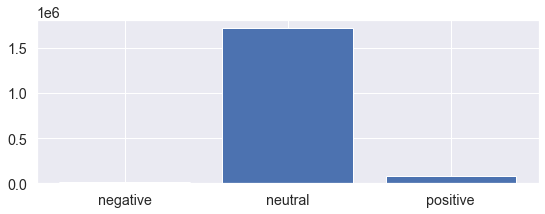

In [23]:
#df.diff().hist(color="k", alpha=0.5, bins=50);
names = ['negative', 'neutral', 'positive']
values = [countNegWord, countNeuWord, countPosWord]

plt.figure(figsize=(9, 3))

#plt.subplot(131)
plt.bar(names, values)

18099
1717895
85730


<BarContainer object of 2 artists>

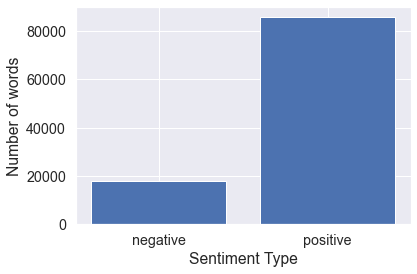

In [24]:
print(countNegWord)
print(countNeuWord)
print(countPosWord)
# function to add value labels
# function to add value labels
def addlabels(x,y):
    for i in range(len(x)):
        plt.text(i,1,y[i])

names = ['negative','positive']
values = [countNegWord, countPosWord]
#addlabels(names, values)
#plt.text(1, values[1], values[1], ha = 'center')
plt.figure()#figsize=(8, 3),
plt.xlabel("Sentiment Type")
plt.ylabel("Number of words")
plt.bar(names, values)

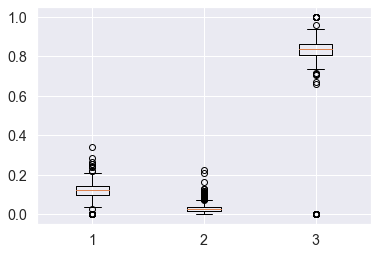

In [25]:
#df
df[['pos']]#, 'neg', 'neu']]
# Creating plot
plt.boxplot(df[['pos', 'neg', 'neu']])
 
# # show plot
plt.show()

In [26]:
# df.to_csv(r'/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/data/stata/sentiment.csv', index = False)
df.to_csv(r'/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/data/stata/sentiment.csv', index = False)


In [27]:
df["sentiment"].dropna(how='all', inplace = True)#values#.to_string().(" ")
#df[['date' 'sentiment']] = pd.DataFrame([ x.split(' ') for x in df['_id'].tolist() ])


In [28]:
# sentiment_array = df["sentiment"].values
#     for line in df["sentiment"]:
#         line = line.rstrip('\n' + '').split(':')
#         # If line is just empty
#         if line != ['']:
#             print line
# filter(bool, sentiment_array)
# print(sentiment_array)

Total Neg=18.980999999999966 | Total Neu=485.94300000000055 | Total Pos=72.04999999999995


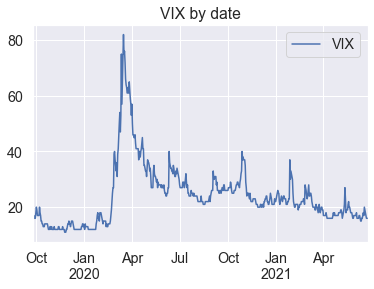

In [29]:
#plt.figure();
#df['sentiment'] = df['ForGraph']#.ewm(span=20).mean()
#print(df.values)
#senDF = df.values
#senDF.all.hist(color="k", alpha=0.5, bins=50);

print("Total Neg="+str(countNeg)+" | Total Neu="+str(countNeu)+" | Total Pos="+str(countPos))


fig = df[['VIX']].plot(title='VIX by date').get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/VIX.png")


In [30]:
df[['sentiment']]

,sentiment
2019-09-25,87.603306
2019-09-26,84.285714
2019-09-27,76.086957
2019-09-28,60.0
2019-09-29,87.719298
...,...
2021-06-20,100.0
2021-06-21,92.571429
2021-06-22,80.0
2021-06-23,91.812865


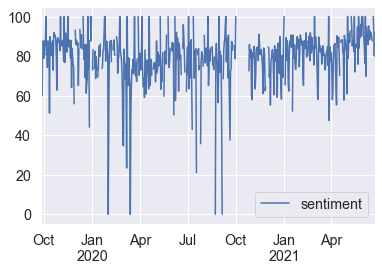

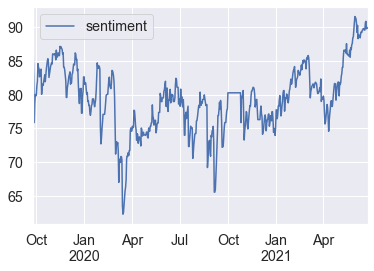

In [31]:
df[['sentiment']] =df[['sentiment']].apply(pd.to_numeric)
df[['sentiment']].plot()

df[['sentiment']].ewm(span=20).mean().plot()
#ts=pd.Series(df['sentiment'], index=pd.date_range("25/09/2019", periods=569))
#ts.plot()
# dfplot = df[['sentiment']].plot(title='sentiment by date').apply(pd.to_numeric) 
# fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/sentiment.png")

# import matplotlib.pyplot as plt
















# fig = df[['VIX','sentiment']].plot(title='sentiment by date', secondary_y=True).get_figure()
# dfplot.set_ylim(50, 100)

#sns.boxplot(x='diagnosis', y='area_mean', data=df)
#df.at[date, 'pos'].plot(title='Sentiment by date')
# ts=pd.Series(df['VIX'])#, index=pd.date_range("25/09/2019", periods=569))
# ts.plot()
# df_vix.diff().hist(color="k", alpha=0.5, bins=50);
# ts.plot()
#predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()


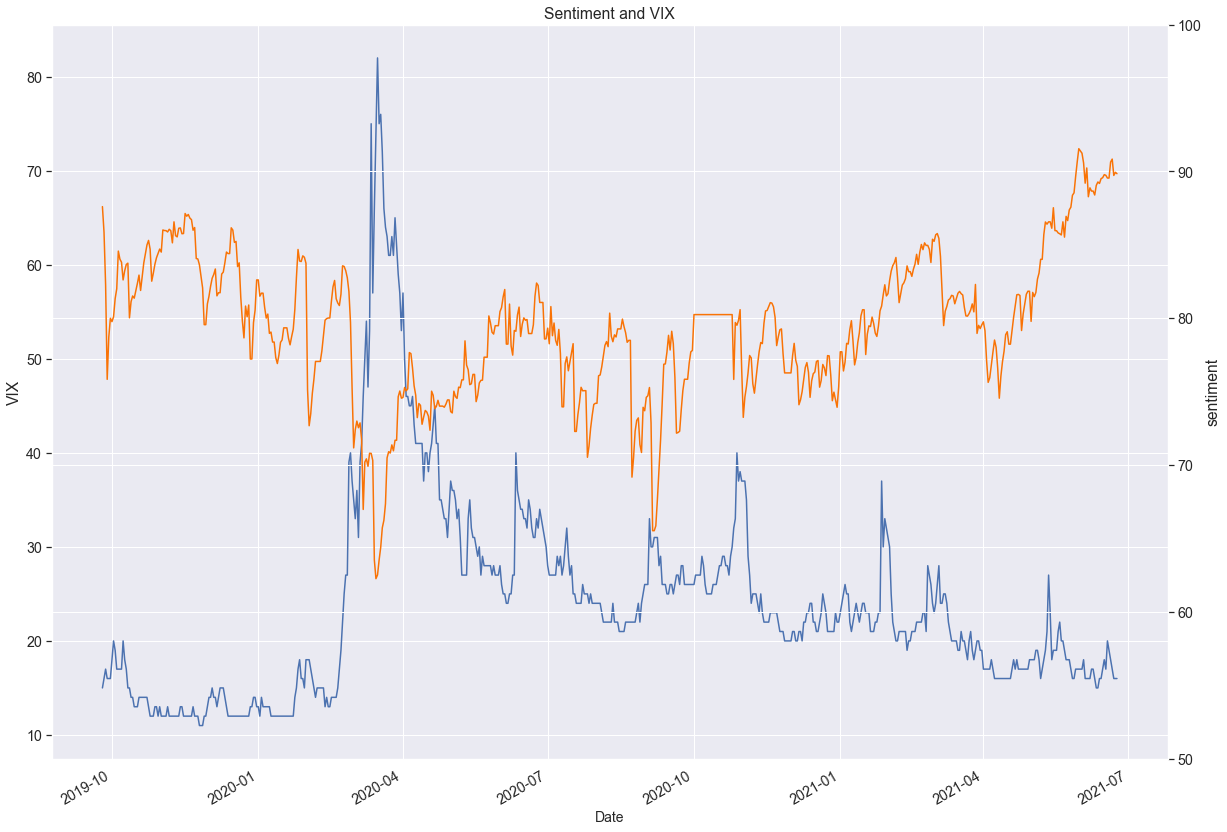

In [32]:
import matplotlib.pyplot as plt
#df[['sentiment']] = df[['sentiment']].ewm(span=20)
fig, ax1 = plt.subplots(figsize=(20,15))
ax1.plot(df[['VIX']])
ax1.set_xlabel("Date",fontsize=14)
ax1.set_title("Sentiment and VIX")
ax1.set_ylabel("VIX")
ax2 = ax1.twinx()
ax2.plot(df[['sentiment']].ewm(span=20).mean(), color='#f97306')# color='#e50000')
ax2.set_ylim([50, 100])
ax2.set_ylabel("sentiment")
fig.autofmt_xdate()
fig = ax2.get_figure()

fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/sentimentVIX.png")

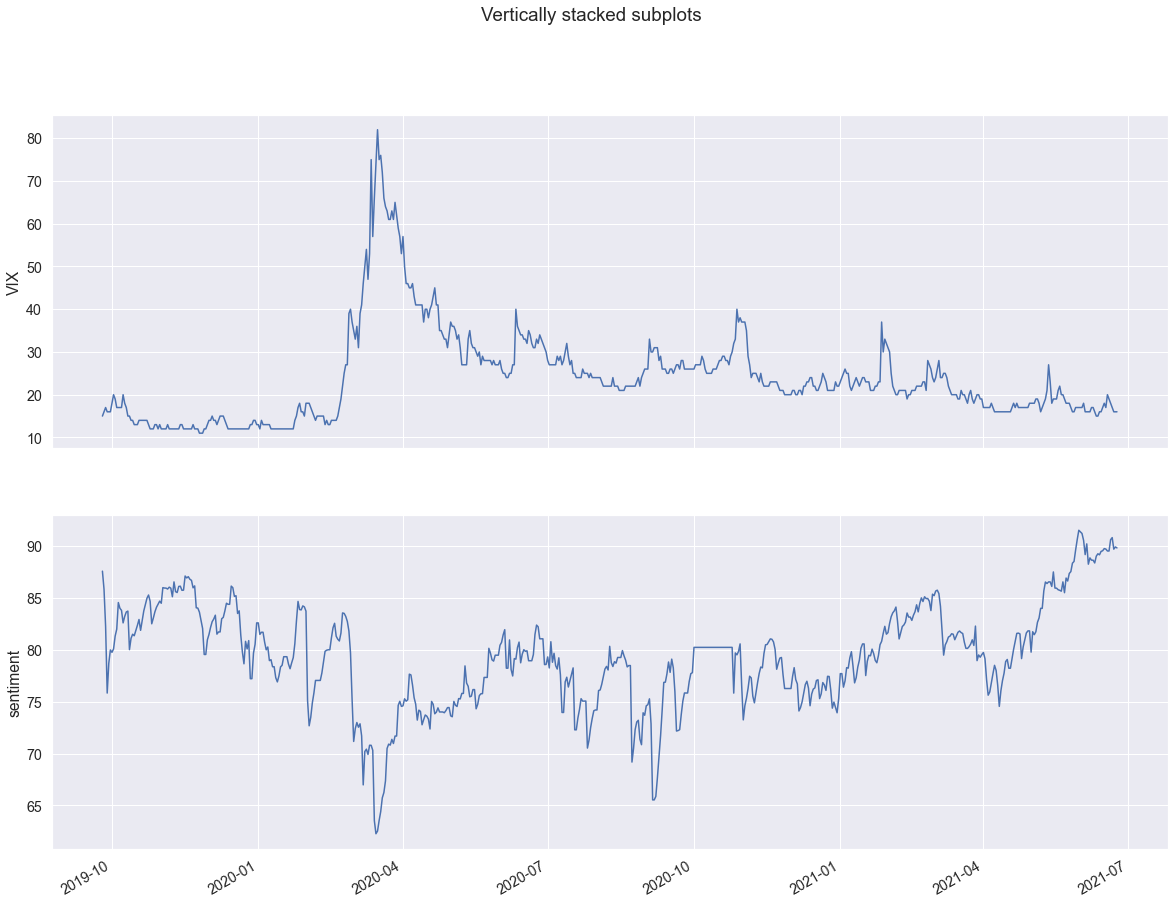

In [33]:
fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('Vertically stacked subplots')
fig.autofmt_xdate()
axs[0].set_ylabel("VIX")
axs[0].plot(df[['VIX']])
axs[1].set_ylabel("sentiment")
axs[1].plot(df[['sentiment']].ewm(span=20).mean())
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/sentiment_VIX.png")

In [34]:
df[['VIX', 'compound', 'neg', 'neu', 'pos', 'sentiment']]

,VIX,compound,neg,neu,pos,sentiment
2019-09-25,15,1.0,0.015,0.879,0.106,87.603306
2019-09-26,16,1.0,0.022,0.859,0.118,84.285714
2019-09-27,17,0.9998,0.033,0.862,0.105,76.086957
2019-09-28,16,0.9912,0.05,0.874,0.075,60.000000
2019-09-29,16,1.0,0.014,0.887,0.1,87.719298
...,...,...,...,...,...,...
2021-06-20,18,0.9907,0.0,0.818,0.182,100.000000
2021-06-21,17,1.0,0.013,0.825,0.162,92.571429
2021-06-22,16,1.0,0.033,0.835,0.132,80.000000
2021-06-23,16,1.0,0.014,0.829,0.157,91.812865


In [35]:
#df_sentiment = df['sentiment'].apply(np.int)

In [36]:
#df_sentiment

In [37]:
sentence = 'The shooting in Paris killed two'
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
sid
ss = sid.polarity_scores(sentence)
ss

{'neg': 0.474, 'neu': 0.526, 'pos': 0.0, 'compound': -0.6705}

In [101]:
# import plotly.express as px
# fig = px.box(df, y="VIX")
# fig.show()
df
#sns.boxplot(y='neu', data=df)




# df_sentiment['sentiment'] = df
# target_dist = sns.factorplot(x='data',data=df_sentiment, kind="count", size=20, aspect=1.5, palette="PuBuGn_d")
#target_dist.plot()
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/target_dist_vix.png')
# target_dist = sns.factorplot(x="sentiment", data=df, kind="count", size=20, aspect=1.5, palette="PuBuGn_d")
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/target_dist_sentiment.png')

,VIX,compound,neg,neu,pos,sentiment
2019-09-25,15,1.0,0.015,0.879,0.106,87.603306
2019-09-26,16,1.0,0.022,0.859,0.118,84.285714
2019-09-27,17,0.9998,0.033,0.862,0.105,76.086957
2019-09-28,16,0.9912,0.05,0.874,0.075,60.000000
2019-09-29,16,1.0,0.014,0.887,0.1,87.719298
...,...,...,...,...,...,...
2021-06-20,18,0.9907,0.0,0.818,0.182,100.000000
2021-06-21,17,1.0,0.013,0.825,0.162,92.571429
2021-06-22,16,1.0,0.033,0.835,0.132,80.000000
2021-06-23,16,1.0,0.014,0.829,0.157,91.812865


In [103]:
fig, axes = plt.subplots(10,2,figsize=(25,75))
for i,col in enumerate(plot_columns):
    sns.regplot(col,'VKOSPI',data=train_org, ax=axes[i,0]) # regression plot
    sns.kdeplot(train_org[col],train_org['VKOSPI'],shade=True, ax=axes[i,1]) # kernel density e

NameError: name 'plot_columns' is not defined

In [39]:
# Checking date for empty strings
for date, row in df_vix.T.iteritems():
    if type(df_vix.loc[date, 'articles']).__name__ == 'str':
        print(date)

2019-12-30 00:00:00
2020-01-24 00:00:00
2020-08-27 00:00:00
2020-06-17 00:00:00
2020-01-05 00:00:00
2019-10-09 00:00:00
2020-05-15 00:00:00
2020-02-20 00:00:00
2019-09-25 00:00:00
2021-01-02 00:00:00
2021-01-04 00:00:00
2020-02-18 00:00:00
2019-10-06 00:00:00
2019-11-27 00:00:00
2019-10-13 00:00:00
2021-03-31 00:00:00
2021-04-23 00:00:00
2020-04-13 00:00:00
2021-02-27 00:00:00
2020-04-27 00:00:00
2020-02-19 00:00:00
2021-02-09 00:00:00
2019-11-29 00:00:00
2020-03-29 00:00:00
2020-04-03 00:00:00
2020-10-26 00:00:00
2021-04-19 00:00:00
2020-09-23 00:00:00
2020-03-09 00:00:00
2020-05-03 00:00:00
2021-01-20 00:00:00
2021-05-05 00:00:00
2021-06-18 00:00:00
2021-04-27 00:00:00
2019-10-29 00:00:00
2020-07-12 00:00:00
2020-03-11 00:00:00
2020-04-19 00:00:00
2021-01-03 00:00:00
2021-06-05 00:00:00
2021-01-08 00:00:00
2021-01-28 00:00:00
2020-09-08 00:00:00
2020-06-15 00:00:00
2020-11-07 00:00:00
2020-12-11 00:00:00
2019-10-16 00:00:00
2021-04-11 00:00:00
2020-01-20 00:00:00
2021-02-23 00:00:00


In [40]:
df

,VIX,compound,neg,neu,pos,sentiment
2019-09-25,15,1.0,0.015,0.879,0.106,87.603306
2019-09-26,16,1.0,0.022,0.859,0.118,84.285714
2019-09-27,17,0.9998,0.033,0.862,0.105,76.086957
2019-09-28,16,0.9912,0.05,0.874,0.075,60.000000
2019-09-29,16,1.0,0.014,0.887,0.1,87.719298
...,...,...,...,...,...,...
2021-06-20,18,0.9907,0.0,0.818,0.182,100.000000
2021-06-21,17,1.0,0.013,0.825,0.162,92.571429
2021-06-22,16,1.0,0.033,0.835,0.132,80.000000
2021-06-23,16,1.0,0.014,0.829,0.157,91.812865


In [41]:
class TextCounts(BaseEstimator, TransformerMixin):
    
    def count_regex(self, pattern, tweet):
        return len(re.findall(pattern, tweet))
    
    def fit(self, X, y=None, **fit_params):
        # fit method is used when specific operations need to be done on the train data, but not on the test data
        return self
    
    def transform(self, X, **transform_params):
        count_words = X.apply(lambda x: self.count_regex(r'\w+', x)) 
        count_mentions = X.apply(lambda x: self.count_regex(r'@\w+', x))
        count_hashtags = X.apply(lambda x: self.count_regex(r'#\w+', x))
        count_capital_words = X.apply(lambda x: self.count_regex(r'\b[A-Z]{2,}\b', x))
        count_excl_quest_marks = X.apply(lambda x: self.count_regex(r'!|\?', x))
        count_urls = X.apply(lambda x: self.count_regex(r'http.?://[^\s]+[\s]?', x))
        # Moreover, it will result in having more words in the tweet
        
        df = pd.DataFrame({'count_words': count_words
                           , 'count_mentions': count_mentions
                           , 'count_hashtags': count_hashtags
                           , 'count_capital_words': count_capital_words
                           , 'count_excl_quest_marks': count_excl_quest_marks
                           , 'count_urls': count_urls
                          })
        
        return df

In [42]:
tc = TextCounts()
#df_eda = tc.fit_transform(df_vix.articles)


In [43]:
def show_dist(df, col):
    print('Descriptive stats for {}'.format(col))
    print('-'*(len(col)+22))
    print(df.groupby('VIX')[col].describe())
    bins = np.arange(df[col].min(), df[col].max() + 1)
    g = sns.FacetGrid(df, col='VIX', size=5, hue='VIX', palette="PuBuGn_d")
    g = g.map(sns.distplot, col, kde=False, norm_hist=True, bins=bins)
    plt.show()

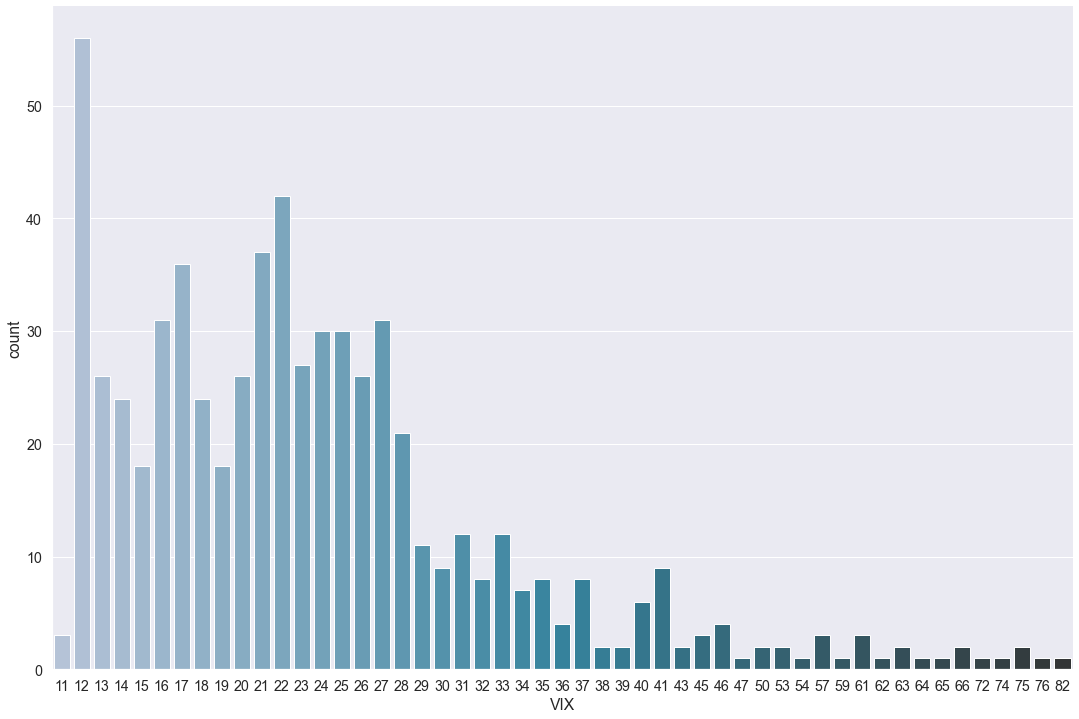

In [44]:
#df_vixs=df[['VIX']]
df_vixs=df_vix
target_dist = sns.factorplot(x="VIX", data=df_vixs, kind="count", size=10, aspect=1.5, palette="PuBuGn_d")
plt.show();
target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/VIX_Histogram.png')

In [45]:
#df[['sentiment']])#.add(0.5).round().apply(int).options.display.float_format = '{:,.0f}'.format
#round()
df[['sentiment']] = pd.to_numeric(df['sentiment'])

In [46]:
df[['sentiment']].round()

,sentiment
2019-09-25,88.0
2019-09-26,84.0
2019-09-27,76.0
2019-09-28,60.0
2019-09-29,88.0
...,...
2021-06-20,100.0
2021-06-21,93.0
2021-06-22,80.0
2021-06-23,92.0


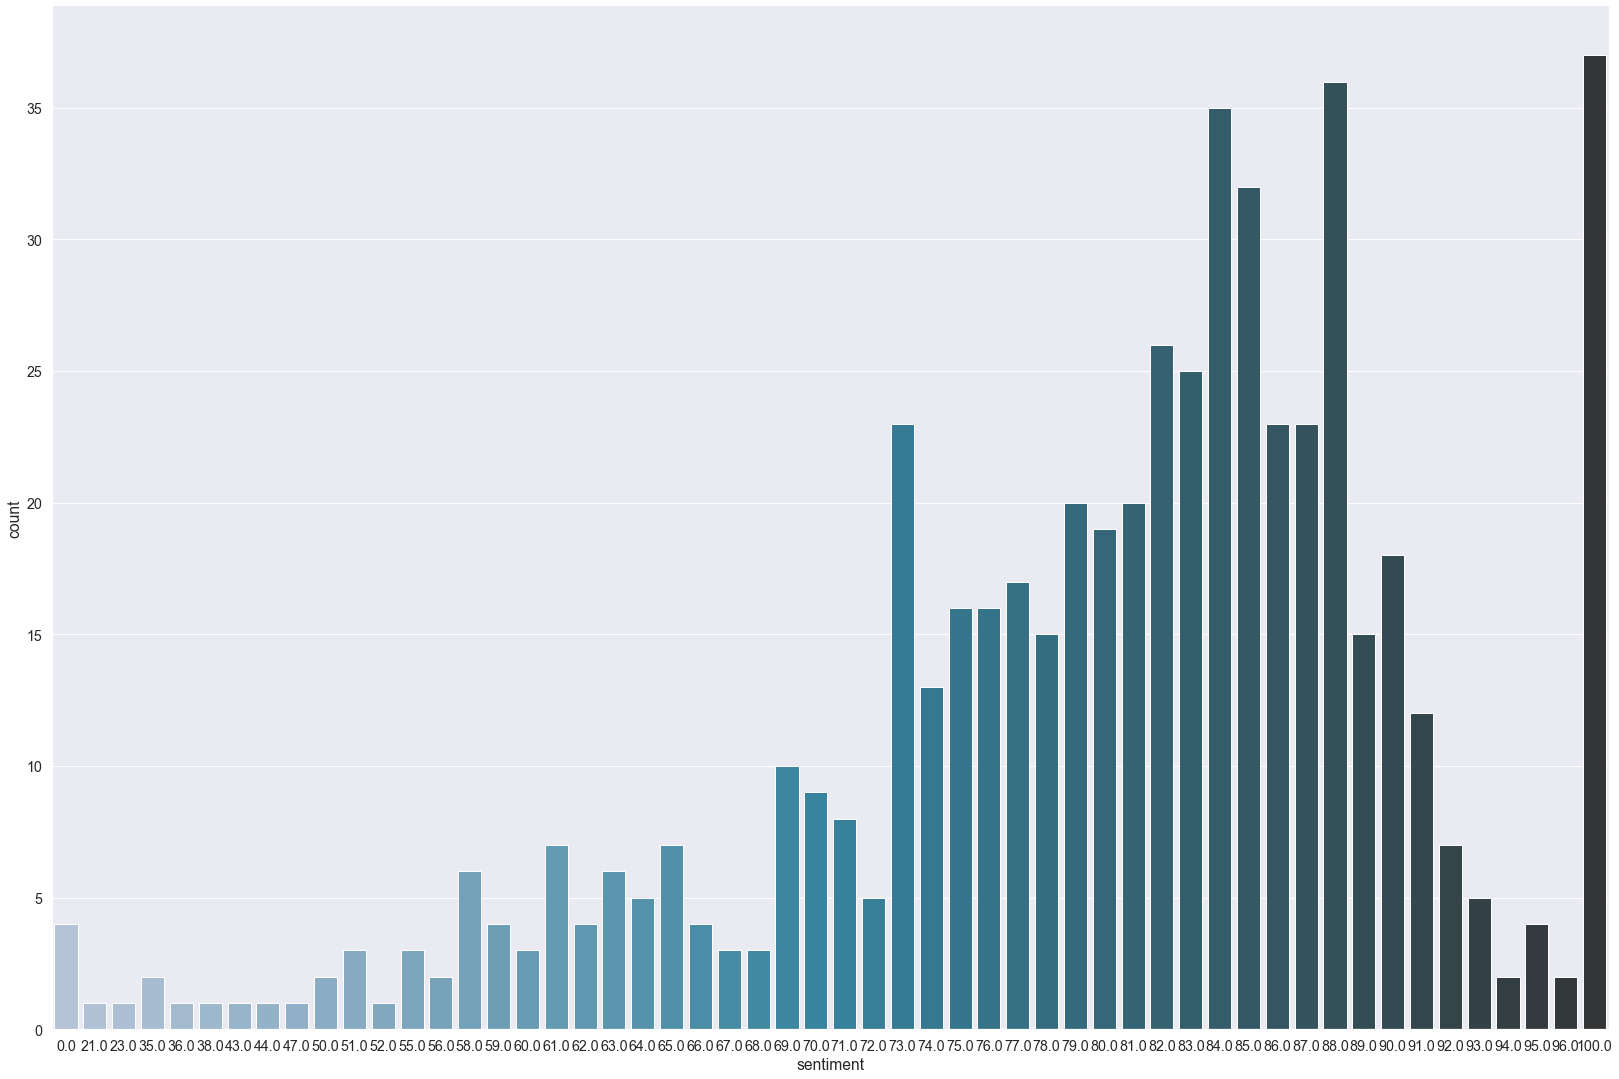

In [47]:
target_dist = sns.factorplot(x="sentiment", data=df[['sentiment']].round(0), kind="count", size=15, aspect=1.5, palette="PuBuGn_d")
plt.show();
target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/sentiment_Histogram.png')

In [48]:
#show_dist(df_vixs, 'VIX')

In [49]:
df

,VIX,compound,neg,neu,pos,sentiment
2019-09-25,15,1.0,0.015,0.879,0.106,87.603306
2019-09-26,16,1.0,0.022,0.859,0.118,84.285714
2019-09-27,17,0.9998,0.033,0.862,0.105,76.086957
2019-09-28,16,0.9912,0.05,0.874,0.075,60.000000
2019-09-29,16,1.0,0.014,0.887,0.1,87.719298
...,...,...,...,...,...,...
2021-06-20,18,0.9907,0.0,0.818,0.182,100.000000
2021-06-21,17,1.0,0.013,0.825,0.162,92.571429
2021-06-22,16,1.0,0.033,0.835,0.132,80.000000
2021-06-23,16,1.0,0.014,0.829,0.157,91.812865


In [50]:
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'

train = df.loc[train_start_date : train_end_date]
print(test_start_date)
test = df.loc[test_start_date:test_end_date]
print(test_end_date)


2019-09-25
2021-06-24


In [51]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [52]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    print(date)
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

2019-09-25 00:00:00
2019-09-26 00:00:00
2019-09-27 00:00:00
2019-09-28 00:00:00
2019-09-29 00:00:00
2019-09-30 00:00:00
2019-10-01 00:00:00
2019-10-02 00:00:00
2019-10-03 00:00:00
2019-10-04 00:00:00
2019-10-05 00:00:00
2019-10-06 00:00:00
2019-10-07 00:00:00
2019-10-08 00:00:00
2019-10-09 00:00:00
2019-10-10 00:00:00
2019-10-11 00:00:00
2019-10-12 00:00:00
2019-10-13 00:00:00
2019-10-14 00:00:00
2019-10-15 00:00:00
2019-10-16 00:00:00
2019-10-17 00:00:00
2019-10-18 00:00:00
2019-10-19 00:00:00
2019-10-20 00:00:00
2019-10-21 00:00:00
2019-10-22 00:00:00
2019-10-23 00:00:00
2019-10-24 00:00:00
2019-10-25 00:00:00
2019-10-26 00:00:00
2019-10-27 00:00:00
2019-10-28 00:00:00
2019-10-29 00:00:00
2019-10-30 00:00:00
2019-10-31 00:00:00
2019-11-01 00:00:00
2019-11-02 00:00:00
2019-11-03 00:00:00
2019-11-04 00:00:00
2019-11-05 00:00:00
2019-11-06 00:00:00
2019-11-07 00:00:00
2019-11-08 00:00:00
2019-11-09 00:00:00
2019-11-10 00:00:00
2019-11-11 00:00:00
2019-11-12 00:00:00
2019-11-13 00:00:00


In [53]:
y_train = pd.DataFrame(train['VIX'])
y_test = pd.DataFrame(test['VIX'])

In [54]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
print("####################### 1 ######################")
print(y_train)
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
rf.fit(numpy_df_train, y_train)

####################### 1 ######################
            VIX
2019-09-25   15
2019-09-26   16
2019-09-27   17
2019-09-28   16
2019-09-29   16
...         ...
2021-06-20   18
2021-06-21   17
2021-06-22   16
2021-06-23   16
2021-06-24   16

[639 rows x 1 columns]
######################## 2 #####################
[[0.015 0.106]
 [0.022 0.118]
 [0.033 0.105]
 ...
 [0.033 0.132]
 [0.014 0.157]
 [0.02  0.162]]
######################## 3 #####################


RandomForestRegressor()

In [55]:
print(rf.feature_importances_)

[0.45373846 0.54626154]


In [56]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [57]:
prediction

array([[16.79833333],
       [17.06      ],
       [29.135     ],
       [21.99666667],
       [17.03266667],
       [18.04      ],
       [26.54      ],
       [29.33471429],
       [19.17      ],
       [18.09666667],
       [17.30666667],
       [18.67      ],
       [20.375     ],
       [23.46      ],
       [16.97      ],
       [17.00666667],
       [20.14      ],
       [16.32      ],
       [15.5       ],
       [15.9       ],
       [15.78      ],
       [17.95      ],
       [18.        ],
       [15.25      ],
       [21.63      ],
       [16.29483333],
       [16.42      ],
       [16.77833333],
       [17.51083333],
       [13.88      ],
       [19.07      ],
       [15.85      ],
       [13.32583333],
       [17.56      ],
       [12.9765    ],
       [14.12      ],
       [14.12      ],
       [15.07      ],
       [17.85      ],
       [19.2689881 ],
       [13.6875    ],
       [17.04      ],
       [16.8       ],
       [15.11075   ],
       [26.655     ],
       [19

In [58]:
contributions

array([[-4.01661263, -3.07275356],
       [-4.29382635, -2.53387318],
       [-3.02073404,  8.26803451],
       ...,
       [ 2.66209929, -7.14979882],
       [-3.2731127 , -2.7812535 ],
       [-4.35531322, -2.77238631]])

In [59]:
import matplotlib.pyplot as plt
%matplotlib inline

In [60]:
print(test_start_date)

idx = pd.date_range(test_start_date, test_end_date)
print(test_end_date)
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'] )

2019-09-25
2021-06-24


In [61]:
predictions_df

,VIX
2019-09-25,16.798333
2019-09-26,17.060000
2019-09-27,29.135000
2019-09-28,21.996667
2019-09-29,17.032667
...,...
2021-06-20,17.560000
2021-06-21,17.660000
2021-06-22,19.400000
2021-06-23,17.833333


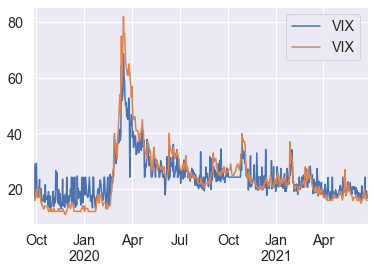

In [62]:
#predictions_df.plot() 
#test['VIX'].plot()

predictions_plot = predictions_df.plot()

fig = y_test.plot(ax = predictions_plot).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_without_smoothing_sp500.png")
#matplotlib.pyplot.savefig("C:\Users\Farid\Documents\Project Options predictions\graphs\random forest without smoothing.png")

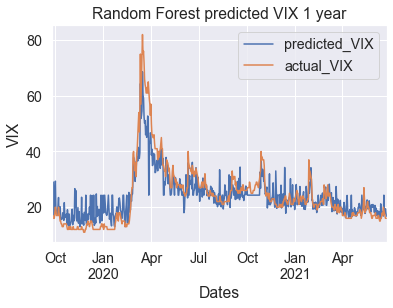

In [63]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year')
ax.set_xlabel("Dates")
ax.set_ylabel("VIX")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_without_smoothing2_sp500.png")

# colors = ['332288', '88CCEE', '44AA99', '117733', '999933', 'DDCC77', 'CC6677', '882255', 'AA4499']

In [64]:
test

,VIX,compound,neg,neu,pos,sentiment
2019-09-25,15,1.0,0.015,0.879,0.106,87.603306
2019-09-26,16,1.0,0.022,0.859,0.118,84.285714
2019-09-27,17,0.9998,0.033,0.862,0.105,76.086957
2019-09-28,16,0.9912,0.05,0.874,0.075,60.000000
2019-09-29,16,1.0,0.014,0.887,0.1,87.719298
...,...,...,...,...,...,...
2021-06-20,18,0.9907,0.0,0.818,0.182,100.000000
2021-06-21,17,1.0,0.013,0.825,0.162,92.571429
2021-06-22,16,1.0,0.033,0.835,0.132,80.000000
2021-06-23,16,1.0,0.014,0.829,0.157,91.812865


In [65]:
# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [66]:
from datetime import datetime, timedelta

temp_date = test_start_date
print(test_start_date)
print(datetime.astimezone)
average_last_5_days_test = 0
total_days = 10
for i in range(total_days):
    average_last_5_days_test += test.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Reducing one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    #print temp_date
average_last_5_days_test = average_last_5_days_test / total_days
print (average_last_5_days_test)

temp_date = test_start_date
average_upcoming_5_days_predicted = 0
for i in range(total_days):
    average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Adding one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    print(temp_date)
average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
print (average_upcoming_5_days_predicted)
#average train.loc['2013-12-31', 'VIX'] - advpredictions_df.loc['2014-01-01', 'VIX']
difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
print (difference_test_predicted_VIX)

2019-09-25
<method 'astimezone' of 'datetime.datetime' objects>
17.0
2019-09-26
2019-09-27
2019-09-28
2019-09-29
2019-09-30
2019-10-01
2019-10-02
2019-10-03
2019-10-04
2019-10-05
21.32040476190476
-4.320404761904761


In [67]:
predictions_df

,VIX
2019-09-25,16.798333
2019-09-26,17.060000
2019-09-27,29.135000
2019-09-28,21.996667
2019-09-29,17.032667
...,...
2021-06-20,17.560000
2021-06-21,17.660000
2021-06-22,19.400000
2021-06-23,17.833333


In [68]:
# Adding 6177 to all the advpredictions_df VIX values
predictions_df['VIX'] = predictions_df['VIX'] + difference_test_predicted_VIX
predictions_df

,VIX
2019-09-25,12.477929
2019-09-26,12.739595
2019-09-27,24.814595
2019-09-28,17.676262
2019-09-29,12.712262
...,...
2021-06-20,13.239595
2021-06-21,13.339595
2021-06-22,15.079595
2021-06-23,13.512929


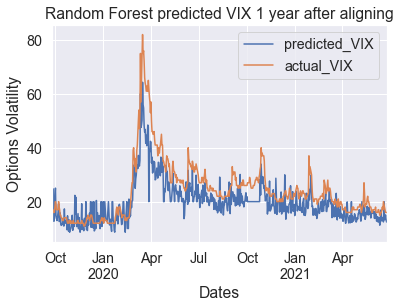

In [69]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year after aligning')
ax.set_xlabel("Dates")
ax.set_ylabel("Options Volatility")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_with_aligning_sp500.png")



# Smoothing the time series data

# Applying EWM pandas to smooth the VIX volatility

In [70]:
predictions_df

,VIX
2019-09-25,12.477929
2019-09-26,12.739595
2019-09-27,24.814595
2019-09-28,17.676262
2019-09-29,12.712262
...,...
2021-06-20,13.239595
2021-06-21,13.339595
2021-06-22,15.079595
2021-06-23,13.512929


In [71]:
predictions_df['ewm'] = predictions_df["VIX"].ewm(span=60).mean()

In [72]:
predictions_df

,VIX,ewm
2019-09-25,12.477929,12.477929
2019-09-26,12.739595,12.610942
2019-09-27,24.814595,16.815164
2019-09-28,17.676262,17.041319
2019-09-29,12.712262,16.116842
...,...,...
2021-06-20,13.239595,14.946190
2021-06-21,13.339595,14.893515
2021-06-22,15.079595,14.899616
2021-06-23,13.512929,14.854151


In [73]:
predictions_df['actual_value'] = test['VIX']
predictions_df['actual_value_ewm'] = predictions_df["actual_value"].ewm(span=60).mean()

In [74]:
predictions_df

,VIX,ewm,actual_value,actual_value_ewm
2019-09-25,12.477929,12.477929,15,15.000000
2019-09-26,12.739595,12.610942,16,15.508333
2019-09-27,24.814595,16.815164,17,16.022220
2019-09-28,17.676262,17.041319,16,16.016384
2019-09-29,12.712262,16.116842,16,16.012885
...,...,...,...,...
2021-06-20,13.239595,14.946190,18,17.794523
2021-06-21,13.339595,14.893515,17,17.768473
2021-06-22,15.079595,14.899616,16,17.710490
2021-06-23,13.512929,14.854151,16,17.654409


In [75]:
# Changing column names
predictions_df.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']

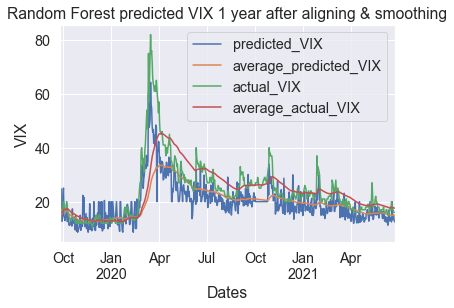

In [76]:
# Now plotting test predictions after smoothing
predictions_plot = predictions_df.plot(title='Random Forest predicted VIX 1 year after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_after_smoothing_var_sp500.png")


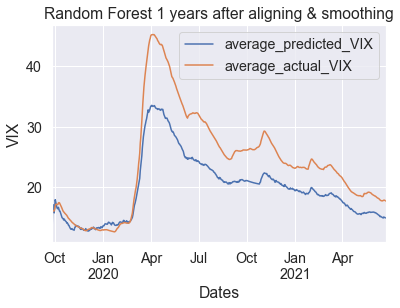

In [77]:
# Plotting just predict and actual average curves
predictions_df_average = predictions_df[['average_predicted_VIX', 'average_actual_VIX']]
predictions_plot = predictions_df_average.plot(title='Random Forest 1 years after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_after_smoothing2_mean_sp500.png")

# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [78]:
def offset_value(test_start_date, test, predictions_df):
    temp_date = test_start_date
    average_last_5_days_test = 0
    average_upcoming_5_days_predicted = 0
    total_days = 10
    for i in range(total_days):
        average_last_5_days_test += test.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_last_5_days_test = average_last_5_days_test / total_days

    temp_date = test_start_date
    for i in range(total_days):
        average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
    difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
    return difference_test_predicted_VIX

# LogisticRegression

#1
20568
26792
####################### 1 ######################
2019-09-25    15
2019-09-26    16
2019-09-27    17
2019-09-28    16
2019-09-29    16
              ..
2021-06-20    18
2021-06-21    17
2021-06-22    16
2021-06-23    16
2021-06-24    16
Freq: D, Name: VIX, Length: 639, dtype: int64
######################## 2 #####################
[[1.     0.015  0.879  0.106 ]
 [1.     0.022  0.859  0.118 ]
 [0.9998 0.033  0.862  0.105 ]
 ...
 [1.     0.033  0.835  0.132 ]
 [1.     0.014  0.829  0.157 ]
 [0.9999 0.02   0.818  0.162 ]]
######################## 3 #####################
#6
2019-09-25 2021-06-24 2019-09-25 2021-06-24
#7


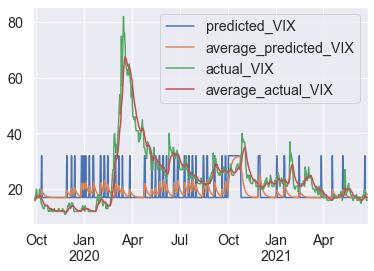

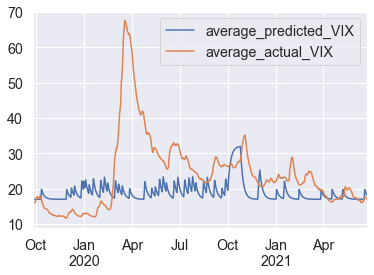

In [79]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []

# Splitting the training and testing data
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date : test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
print("#1")
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
# Linear regression model
lr = LogisticRegression()
print(sys.getsizeof(numpy_df_train))
print(sys.getsizeof(train['VIX']))

print("####################### 1 ######################")
print(train['VIX'])
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
lr.fit(numpy_df_train, train['VIX'])

#   if len(np.sum(train['VIX'])) in [len(train['VIX']),0]:
#       print ("all one class")
#       #do something else
#   else:
#       #OK to proceed
#       lenreg.fit(numpy_df_train, train['VIX'])
#       y_pred = lenreg.predict(numpy_df_train)
#       print (metics.accuracy_score(y_test, y_pred))


print("#6")

prediction = lr.predict(numpy_df_test)
prediction_list.append(prediction)
print (train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date)
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=10).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()
print("#7")
#     predictions_df_list.show()


In [80]:
lr.classes_

array([11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27,
       28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 43, 45, 46,
       47, 50, 53, 54, 57, 59, 61, 62, 63, 64, 65, 66, 72, 74, 75, 76, 82],
      dtype=int64)

In [81]:
lr.coef_[0]

array([0.32467937, 0.02885235, 0.11208413, 0.02472273])

# RandomForestRegressor

<AxesSubplot:>

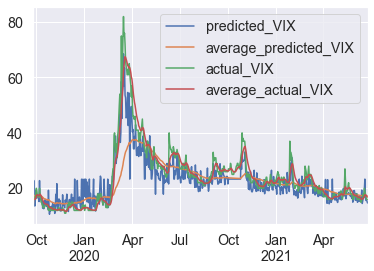

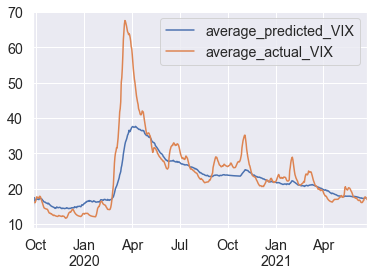

In [82]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
rf = RandomForestRegressor(random_state=0)
rf.fit(numpy_df_train, train['VIX'])
#print rf

prediction, bias, contributions = ti.predict(rf, numpy_df_test)
prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=60).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()


In [83]:
# from IPython.display import Image  
# dot_data = tree.export_graphviz(rf, out_file=None, 
#                      feature_names=['comp', 'neg', 'neu', 'pos'],  
#                      class_names=iris.target_names,  
#                      filled=True, rounded=True,  
#                      special_characters=True)  
# graph = pydotplus.graph_from_dot_data(dot_data)  
# Image(graph.create_png())

# MLP Classifier

<AxesSubplot:>

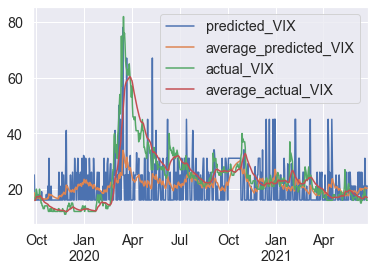

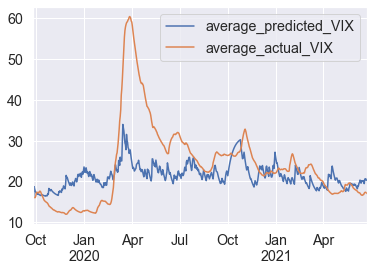

In [84]:
from sklearn.neural_network import MLPClassifier
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

# Generating models
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                        solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc.fit(numpy_df_train, train['VIX'])   
prediction = mlpc.predict(numpy_df_test)

prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=20).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()
    

In [85]:

#my addition
# import matplotlib.pyplot as plt
# from sklearn.datasets import make_blobs

# n_samples = 200
# blob_centers = ([1, 1], [3, 4], [1, 3.3], [3.5, 1.8])
# data, labels = make_blobs(n_samples=n_samples, 
#                           centers=blob_centers, 
#                           cluster_std=0.5,
#                           random_state=0)


# colours = ('green', 'orange', "blue", "magenta")
# fig, ax = plt.subplots()

# for n_class in range(len(blob_centers)):
#     ax.scatter(data[labels==n_class][:, 0], 
#                data[labels==n_class][:, 1], 
#                c=colours[n_class], 
#                s=30, 
#                label=str(n_class))

In [86]:
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='tanh', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False)
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False) # span = 20
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 50), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False)
                     

<AxesSubplot:>

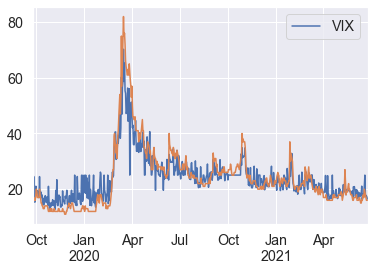

In [87]:
# checking the performance of training data itself
prediction, bias, contributions = ti.predict(rf, numpy_df_train)
idx = pd.date_range(train_start_date, train_end_date)
predictions_df1 = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])
predictions_df1.plot()
train['VIX'].plot()